# IP_GFP + GV_GFP UMAP: cells dominated by four prioritized cNMF programs

This notebook is adapted from `jesse_umap.ipynb` for the selected mouse **K = 30, density threshold = 2.0** model.

It highlights a cell only when its **global dominant program across all 30 cNMF programs** is one of:

- **P15** — endothelial homeostasis / angiogenesis
- **P9** — vascular migration / BMP–TGFβ / angiogenesis
- **P6** — inflammatory adhesion / extracellular matrix
- **P12** — sGC–cGMP / contractile remodeling

All other cells are plotted as a light-gray background.

The notebook outputs:

1. one combined IP_GFP + GV_GFP UMAP;
2. one two-panel UMAP split by mouse;
3. a cell-level CSV with dominant-program assignments;
4. summary tables by program and mouse;
5. Illustrator-editable PDF and SVG figures.

No minimum program-usage threshold is applied by default. Thus, every cell whose maximum cNMF usage is one of the four programs is highlighted.

In [1]:
# Set thread limits before importing NumPy/SciPy.
import os

for variable in [
    "OMP_NUM_THREADS",
    "OPENBLAS_NUM_THREADS",
    "MKL_NUM_THREADS",
    "BLIS_NUM_THREADS",
    "NUMEXPR_NUM_THREADS",
]:
    os.environ.setdefault(variable, "1")

os.environ.setdefault("PYTHONNOUSERSITE", "1")


'1'

In [2]:
from __future__ import annotations

from pathlib import Path
import re
import sys
import warnings

import anndata as ad
from IPython.display import display
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import muon as mu
import numpy as np
import pandas as pd
import scipy.sparse as sp

warnings.filterwarnings("ignore")

# Illustrator-editable text in PDF/SVG.
mpl.rcParams.update(
    {
        "font.family": "DejaVu Sans",
        "font.size": 8,
        "figure.dpi": 150,
        "savefig.dpi": 300,
        "savefig.bbox": "tight",
        "savefig.pad_inches": 0.03,
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
        "svg.fonttype": "none",
    }
)

print("Python:", sys.version.split()[0])


/oak/stanford/groups/engreitz/Users/tri/envs/sc-dl/lib/python3.11/site-packages/muon/_core/preproc.py:31: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  if Version(scanpy.__version__) < Version("1.10"):


Python: 3.11.14


## Configuration

In [3]:
# ---------------------------------------------------------------------
# Selected K30/density-threshold-2.0 model
# ---------------------------------------------------------------------
BASE = Path(
    "/oak/stanford/groups/engreitz/Users/tri/10xPerturbSeq/"
    "analysis/250507_ePAH1_NovaSeq/CRISPR_count/"
    "IP_GV_unified_sceptre_cnmf_no_celltype"
)

RUN_NAME = "IP_GV_skcnmf_K30_dt2_0_n100"
RUN_ROOT = BASE / "PerturbNMF" / "results" / RUN_NAME

H5MU_PATH = (
    RUN_ROOT
    / "Inference"
    / "adata"
    / "cNMF_30_2_0.h5mu"
)

# Fallback UMAP source if X_umap is not retained in the compiled H5MU.
PREPARED_H5AD_PATH = (
    BASE
    / "PerturbNMF"
    / "input"
    / "IP_GFP_GV_GFP_guide_positive_PerturbNMF_input.h5ad"
)

OUTPUT_DIR = (
    RUN_ROOT
    / "Evaluation"
    / "30_2_0"
    / "selected_program_umap"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ---------------------------------------------------------------------
# Four prioritized programs
# ---------------------------------------------------------------------
SELECTED_PROGRAMS = [15, 9, 6, 12]

PROGRAM_LABELS = {
    15: "endothelial homeostasis / angiogenesis",
    9: "vascular migration / BMP–TGFβ / angiogenesis",
    6: "inflammatory adhesion / ECM",
    12: "sGC–cGMP / contractile remodeling",
}

# Distinct, colorblind-conscious colors.
PROGRAM_COLORS = {
    15: "#1F4E79",  # dark blue
    9: "#E69F00",   # orange
    6: "#B2182B",   # dark red
    12: "#7B3294",  # purple
}

# A cell is always assigned by its maximum usage across all 30 programs.
# Leave as None to include every selected-program-dominant cell.
# Set a numeric value only if an absolute usage cutoff is desired.
MIN_DOMINANT_USAGE = None

# Figure settings for this approximately 4,000-cell dataset.
BACKGROUND_COLOR = "#D9DDE3"
BACKGROUND_ALPHA = 0.42
BACKGROUND_SIZE = 5.0

FOREGROUND_ALPHA = 0.95
FOREGROUND_SIZE = 14.0
FOREGROUND_EDGEWIDTH = 0.0
RASTERIZE_FOREGROUND = False

USE_WHITE_HALO = True
HALO_SIZE = 25.0
HALO_ALPHA = 0.85

ANNOTATE_PROGRAMS = True
LABEL_FONT_SIZE = 7.5

COMBINED_FIGSIZE = (5.7, 4.8)
PER_MOUSE_FIGSIZE = (9.0, 4.2)

OUTPUT_STEM = "IP_GV_global_dominant_P15_P9_P6_P12"

print("H5MU:", H5MU_PATH)
print("Prepared H5AD fallback:", PREPARED_H5AD_PATH)
print("Output directory:", OUTPUT_DIR)


H5MU: /oak/stanford/groups/engreitz/Users/tri/10xPerturbSeq/analysis/250507_ePAH1_NovaSeq/CRISPR_count/IP_GV_unified_sceptre_cnmf_no_celltype/PerturbNMF/results/IP_GV_skcnmf_K30_dt2_0_n100/Inference/adata/cNMF_30_2_0.h5mu
Prepared H5AD fallback: /oak/stanford/groups/engreitz/Users/tri/10xPerturbSeq/analysis/250507_ePAH1_NovaSeq/CRISPR_count/IP_GV_unified_sceptre_cnmf_no_celltype/PerturbNMF/input/IP_GFP_GV_GFP_guide_positive_PerturbNMF_input.h5ad
Output directory: /oak/stanford/groups/engreitz/Users/tri/10xPerturbSeq/analysis/250507_ePAH1_NovaSeq/CRISPR_count/IP_GV_unified_sceptre_cnmf_no_celltype/PerturbNMF/results/IP_GV_skcnmf_K30_dt2_0_n100/Evaluation/30_2_0/selected_program_umap


## Helper functions

In [4]:
def dense_array(matrix) -> np.ndarray:
    if sp.issparse(matrix):
        return matrix.toarray()
    if hasattr(matrix, "toarray"):
        return matrix.toarray()
    return np.asarray(matrix)


def infer_program_ids(var_names: pd.Index) -> list[int]:
    """Infer 1-based program numbers from cNMF variable names."""
    parsed = []
    for value in var_names.astype(str):
        match = re.search(r"(\d+)$", value)
        parsed.append(int(match.group(1)) if match else None)

    n_programs = len(var_names)

    if all(value is not None for value in parsed):
        parsed_int = [int(value) for value in parsed]
        if len(set(parsed_int)) == n_programs:
            if set(parsed_int) == set(range(n_programs)):
                # Convert a 0-based naming scheme to P1..PK.
                return [value + 1 for value in parsed_int]
            return parsed_int

    print(
        "Could not infer unique program IDs from var_names; "
        "using cNMF column order as P1..PK."
    )
    return list(range(1, n_programs + 1))


def align_obsm_to_target(
    source,
    target_obs_names: pd.Index,
    key: str = "X_umap",
) -> np.ndarray:
    if key not in source.obsm:
        raise KeyError(f"{key!r} is absent from source.obsm.")

    source_index = pd.Index(source.obs_names)
    target_index = pd.Index(target_obs_names)

    if not source_index.is_unique or not target_index.is_unique:
        raise ValueError("Cell indexes must be unique.")

    missing = target_index.difference(source_index)
    if len(missing):
        raise ValueError(
            f"{len(missing)} target cells are absent from the UMAP source. "
            f"Examples: {missing[:10].tolist()}"
        )

    positions = source_index.get_indexer(target_index)
    coordinates = np.asarray(source.obsm[key])[positions, :2]

    if coordinates.shape != (len(target_index), 2):
        raise ValueError(
            f"Aligned UMAP has unexpected shape {coordinates.shape}."
        )
    return coordinates


def resolve_umap(
    *,
    mdata,
    cnmf,
    rna,
    prepared_h5ad_path: Path,
) -> tuple[np.ndarray, str]:
    """Use an H5MU UMAP when available, otherwise align the prepared H5AD."""
    if "X_umap" in cnmf.obsm:
        return (
            align_obsm_to_target(
                cnmf,
                pd.Index(cnmf.obs_names),
                "X_umap",
            ),
            "cNMF.obsm['X_umap']",
        )

    if "X_umap" in rna.obsm:
        return (
            align_obsm_to_target(
                rna,
                pd.Index(cnmf.obs_names),
                "X_umap",
            ),
            "rna.obsm['X_umap']",
        )

    if "X_umap" in mdata.obsm:
        coordinates = np.asarray(mdata.obsm["X_umap"])
        if coordinates.shape[0] != cnmf.n_obs:
            raise ValueError(
                "MuData X_umap does not have the expected number of cells."
            )
        return coordinates[:, :2], "mdata.obsm['X_umap']"

    if not prepared_h5ad_path.exists():
        raise FileNotFoundError(
            "No X_umap was found in the H5MU and the prepared H5AD "
            f"does not exist: {prepared_h5ad_path}"
        )

    prepared = ad.read_h5ad(prepared_h5ad_path, backed="r")
    try:
        coordinates = align_obsm_to_target(
            prepared,
            pd.Index(cnmf.obs_names),
            "X_umap",
        )
    finally:
        prepared.file.close()

    return coordinates, str(prepared_h5ad_path)


def resolve_obs_column(
    key_candidates: list[str],
    *,
    cnmf,
    rna,
) -> tuple[pd.Series, str]:
    for key in key_candidates:
        if key in cnmf.obs:
            return (
                pd.Series(
                    cnmf.obs[key].to_numpy(),
                    index=cnmf.obs_names,
                    name=key,
                ),
                f"cNMF.obs[{key!r}]",
            )
        if key in rna.obs:
            values = rna.obs.loc[cnmf.obs_names, key]
            return (
                pd.Series(
                    values.to_numpy(),
                    index=cnmf.obs_names,
                    name=key,
                ),
                f"rna.obs[{key!r}]",
            )
    raise KeyError(
        f"None of the requested obs columns exists: {key_candidates}"
    )


def add_program_labels(
    ax,
    dataframe: pd.DataFrame,
    selected_programs: list[int],
) -> None:
    if not ANNOTATE_PROGRAMS:
        return

    for program in selected_programs:
        current = dataframe.loc[
            dataframe["is_prioritized"]
            & (dataframe["dominant_program"] == program)
        ]
        if current.empty:
            continue

        x_position = float(current["UMAP1"].median())
        y_position = float(current["UMAP2"].median())

        ax.text(
            x_position,
            y_position,
            f"P{program}",
            ha="center",
            va="center",
            fontsize=LABEL_FONT_SIZE,
            fontweight="bold",
            color=PROGRAM_COLORS[program],
            bbox={
                "boxstyle": "round,pad=0.18",
                "facecolor": "white",
                "edgecolor": PROGRAM_COLORS[program],
                "linewidth": 0.7,
                "alpha": 0.86,
            },
            zorder=5,
        )


def draw_selected_program_umap(
    ax,
    dataframe: pd.DataFrame,
    *,
    title: str,
    show_legend: bool = True,
    fixed_limits: tuple[tuple[float, float], tuple[float, float]] | None = None,
) -> None:
    background = ~dataframe["is_prioritized"].to_numpy()

    ax.scatter(
        dataframe.loc[background, "UMAP1"],
        dataframe.loc[background, "UMAP2"],
        s=BACKGROUND_SIZE,
        c=BACKGROUND_COLOR,
        alpha=BACKGROUND_ALPHA,
        linewidths=0,
        edgecolors="none",
        rasterized=True,
        zorder=1,
    )

    for program in SELECTED_PROGRAMS:
        mask = (
            dataframe["is_prioritized"]
            & (dataframe["dominant_program"] == program)
        ).to_numpy()

        if USE_WHITE_HALO and mask.any():
            ax.scatter(
                dataframe.loc[mask, "UMAP1"],
                dataframe.loc[mask, "UMAP2"],
                s=HALO_SIZE,
                c="white",
                alpha=HALO_ALPHA,
                linewidths=0,
                edgecolors="none",
                rasterized=RASTERIZE_FOREGROUND,
                zorder=2,
            )

        ax.scatter(
            dataframe.loc[mask, "UMAP1"],
            dataframe.loc[mask, "UMAP2"],
            s=FOREGROUND_SIZE,
            c=PROGRAM_COLORS[program],
            alpha=FOREGROUND_ALPHA,
            linewidths=FOREGROUND_EDGEWIDTH,
            edgecolors="none",
            rasterized=RASTERIZE_FOREGROUND,
            zorder=3,
        )

    add_program_labels(ax, dataframe, SELECTED_PROGRAMS)

    ax.set_title(title, fontsize=9, pad=6)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_aspect("equal")

    for spine in ax.spines.values():
        spine.set_visible(False)

    if fixed_limits is not None:
        ax.set_xlim(*fixed_limits[0])
        ax.set_ylim(*fixed_limits[1])

    if show_legend:
        legend_elements = [
            Line2D(
                [0],
                [0],
                marker="o",
                linestyle="",
                markersize=5,
                markerfacecolor=BACKGROUND_COLOR,
                markeredgewidth=0,
                alpha=0.85,
                label="Other dominant programs",
            )
        ]
        for program in SELECTED_PROGRAMS:
            n_cells = int(
                (
                    dataframe["is_prioritized"]
                    & (dataframe["dominant_program"] == program)
                ).sum()
            )
            legend_elements.append(
                Line2D(
                    [0],
                    [0],
                    marker="o",
                    linestyle="",
                    markersize=5,
                    markerfacecolor=PROGRAM_COLORS[program],
                    markeredgewidth=0,
                    label=(
                        f"P{program}: {PROGRAM_LABELS[program]} "
                        f"(n={n_cells:,})"
                    ),
                )
            )

        ax.legend(
            handles=legend_elements,
            loc="center left",
            bbox_to_anchor=(1.02, 0.5),
            frameon=False,
            fontsize=7.2,
            handletextpad=0.5,
            borderaxespad=0,
        )


## Load the selected cNMF model and assign global dominant programs

In [5]:
if not H5MU_PATH.exists():
    raise FileNotFoundError(H5MU_PATH)

print("Loading:", H5MU_PATH)
mdata = mu.read_h5mu(H5MU_PATH)

if "cNMF" not in mdata.mod or "rna" not in mdata.mod:
    raise KeyError(
        f"Expected 'cNMF' and 'rna' modalities; found {list(mdata.mod)}"
    )

cnmf = mdata["cNMF"]
rna = mdata["rna"]

if cnmf.n_obs != rna.n_obs:
    raise ValueError("cNMF and RNA modalities have different cell counts.")
if not cnmf.obs_names.equals(rna.obs_names):
    raise ValueError("cNMF and RNA cell order differs.")

scores = dense_array(cnmf.X).astype(float)
if scores.shape != (cnmf.n_obs, cnmf.n_vars):
    raise ValueError(
        f"Unexpected cNMF score shape {scores.shape}; "
        f"expected {(cnmf.n_obs, cnmf.n_vars)}."
    )
if not np.isfinite(scores).all():
    raise ValueError("cNMF usage matrix contains NaN or infinite values.")

program_ids = infer_program_ids(pd.Index(cnmf.var_names))
program_to_column = {
    program_id: column
    for column, program_id in enumerate(program_ids)
}

missing_programs = [
    program
    for program in SELECTED_PROGRAMS
    if program not in program_to_column
]
if missing_programs:
    raise ValueError(
        f"Selected programs are absent from cNMF: {missing_programs}. "
        f"Detected program IDs: {program_ids}"
    )

umap_coordinates, umap_source = resolve_umap(
    mdata=mdata,
    cnmf=cnmf,
    rna=rna,
    prepared_h5ad_path=PREPARED_H5AD_PATH,
)

sample, sample_source = resolve_obs_column(
    ["sample", "sample_id", "mouse"],
    cnmf=cnmf,
    rna=rna,
)
sample = sample.astype(str)

dominant_column = np.argmax(scores, axis=1)
dominant_program = np.asarray(
    [program_ids[column] for column in dominant_column],
    dtype=int,
)
dominant_usage = scores[
    np.arange(scores.shape[0]),
    dominant_column,
]

# For nonnegative cNMF usages, also report the fraction of total usage.
if np.nanmin(scores) >= 0:
    total_usage = scores.sum(axis=1)
    dominant_fraction = np.divide(
        dominant_usage,
        total_usage,
        out=np.full_like(dominant_usage, np.nan, dtype=float),
        where=total_usage > 0,
    )
else:
    dominant_fraction = np.full(cnmf.n_obs, np.nan)
    print(
        "Warning: negative cNMF scores detected; dominant_fraction is omitted."
    )

prioritized_mask = np.isin(
    dominant_program,
    SELECTED_PROGRAMS,
)
if MIN_DOMINANT_USAGE is not None:
    prioritized_mask &= dominant_usage >= float(MIN_DOMINANT_USAGE)

cell_table = pd.DataFrame(
    {
        "cell_id": cnmf.obs_names.astype(str),
        "sample": sample.to_numpy(),
        "UMAP1": umap_coordinates[:, 0],
        "UMAP2": umap_coordinates[:, 1],
        "dominant_program": dominant_program,
        "dominant_program_label": [
            PROGRAM_LABELS.get(
                int(program),
                f"P{int(program)}",
            )
            for program in dominant_program
        ],
        "dominant_usage": dominant_usage,
        "dominant_fraction": dominant_fraction,
        "is_prioritized": prioritized_mask,
    }
)

print(mdata)
print("UMAP source:", umap_source)
print("Sample source:", sample_source)
print("Detected program mapping:")
display(
    pd.DataFrame(
        {
            "cNMF_var_name": cnmf.var_names.astype(str),
            "program_id": program_ids,
        }
    )
)


Loading: /oak/stanford/groups/engreitz/Users/tri/10xPerturbSeq/analysis/250507_ePAH1_NovaSeq/CRISPR_count/IP_GV_unified_sceptre_cnmf_no_celltype/PerturbNMF/results/IP_GV_skcnmf_K30_dt2_0_n100/Inference/adata/cNMF_30_2_0.h5mu
MuData object with n_obs × n_vars = 4095 × 16896
  2 modalities
    rna:	4095 x 16866
      obs:	'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'sample_id', 'barcode', 'passes_rna_qc', 'raw_total_guide_umis', 'raw_n_detected_guides', 'total_guide_umis', 'n_detected_guides', 'n_assigned_guides', 'n_assigned_targets', 'assigned_guide_umis', 'assigned_guide_ids', 'assigned_targets', 'guide_assignment_status', 'has_sceptre_guide', 'sample', 'mouse'
      var:	'gene_ids', 'feature_types', 'genome', 'pattern', 'read', 'sequence', 'target_gene_id',

,cNMF_var_name,program_id
0,1,1
1,2,2
2,3,3
3,4,4
4,5,5
5,6,6
6,7,7
7,8,8
8,9,9
9,10,10


## Export dominant-program assignments and summaries

In [6]:
cell_output_path = (
    OUTPUT_DIR / f"{OUTPUT_STEM}_cell_assignments.csv.gz"
)
selected_cell_output_path = (
    OUTPUT_DIR / f"{OUTPUT_STEM}_selected_cells.csv.gz"
)
summary_output_path = (
    OUTPUT_DIR / f"{OUTPUT_STEM}_summary_by_mouse.csv"
)
overall_summary_output_path = (
    OUTPUT_DIR / f"{OUTPUT_STEM}_summary_overall.csv"
)

cell_table.to_csv(
    cell_output_path,
    index=False,
    compression="gzip",
)
cell_table.loc[cell_table["is_prioritized"]].to_csv(
    selected_cell_output_path,
    index=False,
    compression="gzip",
)

summary_by_mouse = []
for sample_name, sample_frame in cell_table.groupby(
    "sample",
    sort=True,
):
    for program in SELECTED_PROGRAMS:
        n_cells = int(
            (
                sample_frame["is_prioritized"]
                & (sample_frame["dominant_program"] == program)
            ).sum()
        )
        summary_by_mouse.append(
            {
                "sample": sample_name,
                "program": f"P{program}",
                "program_number": program,
                "program_label": PROGRAM_LABELS[program],
                "n_cells": n_cells,
                "sample_cells": int(len(sample_frame)),
                "fraction_of_sample_cells": (
                    n_cells / len(sample_frame)
                    if len(sample_frame)
                    else np.nan
                ),
            }
        )

summary_by_mouse = pd.DataFrame(summary_by_mouse)
summary_by_mouse.to_csv(summary_output_path, index=False)

overall_rows = []
for program in SELECTED_PROGRAMS:
    n_cells = int(
        (
            cell_table["is_prioritized"]
            & (cell_table["dominant_program"] == program)
        ).sum()
    )
    overall_rows.append(
        {
            "program": f"P{program}",
            "program_number": program,
            "program_label": PROGRAM_LABELS[program],
            "n_cells": n_cells,
            "total_cells": int(len(cell_table)),
            "fraction_of_all_cells": n_cells / len(cell_table),
        }
    )

overall_summary = pd.DataFrame(overall_rows)
overall_summary.to_csv(overall_summary_output_path, index=False)

print("Overall prioritized-program summary")
display(overall_summary)

print("Summary by mouse")
display(summary_by_mouse)

print("Prioritized cells:", int(cell_table["is_prioritized"].sum()))
print("Background cells:", int((~cell_table["is_prioritized"]).sum()))


Overall prioritized-program summary


,program,program_number,program_label,n_cells,total_cells,fraction_of_all_cells
0,P15,15,endothelial homeostasis / angiogenesis,35,4095,0.008547
1,P9,9,vascular migration / BMP–TGFβ / angiogenesis,55,4095,0.013431
2,P6,6,inflammatory adhesion / ECM,213,4095,0.052015
3,P12,12,sGC–cGMP / contractile remodeling,74,4095,0.018071


Summary by mouse


,sample,program,program_number,program_label,n_cells,sample_cells,fraction_of_sample_cells
0,GV_GFP,P15,15,endothelial homeostasis / angiogenesis,10,1246,0.008026
1,GV_GFP,P9,9,vascular migration / BMP–TGFβ / angiogenesis,16,1246,0.012841
2,GV_GFP,P6,6,inflammatory adhesion / ECM,70,1246,0.056180
3,GV_GFP,P12,12,sGC–cGMP / contractile remodeling,25,1246,0.020064
4,IP_GFP,P15,15,endothelial homeostasis / angiogenesis,25,2849,0.008775
5,IP_GFP,P9,9,vascular migration / BMP–TGFβ / angiogenesis,39,2849,0.013689
6,IP_GFP,P6,6,inflammatory adhesion / ECM,143,2849,0.050193
7,IP_GFP,P12,12,sGC–cGMP / contractile remodeling,49,2849,0.017199


Prioritized cells: 377
Background cells: 3718


## Combined IP_GFP + GV_GFP UMAP

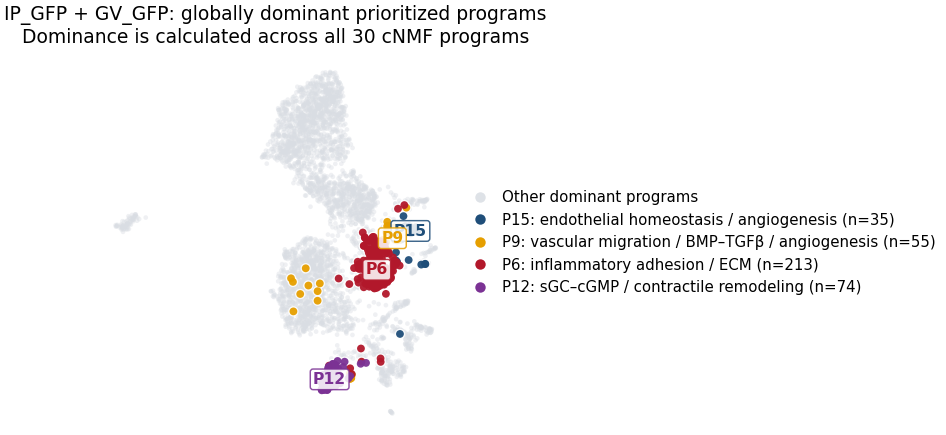

Saved:
/oak/stanford/groups/engreitz/Users/tri/10xPerturbSeq/analysis/250507_ePAH1_NovaSeq/CRISPR_count/IP_GV_unified_sceptre_cnmf_no_celltype/PerturbNMF/results/IP_GV_skcnmf_K30_dt2_0_n100/Evaluation/30_2_0/selected_program_umap/IP_GV_global_dominant_P15_P9_P6_P12_combined.pdf
/oak/stanford/groups/engreitz/Users/tri/10xPerturbSeq/analysis/250507_ePAH1_NovaSeq/CRISPR_count/IP_GV_unified_sceptre_cnmf_no_celltype/PerturbNMF/results/IP_GV_skcnmf_K30_dt2_0_n100/Evaluation/30_2_0/selected_program_umap/IP_GV_global_dominant_P15_P9_P6_P12_combined.svg
/oak/stanford/groups/engreitz/Users/tri/10xPerturbSeq/analysis/250507_ePAH1_NovaSeq/CRISPR_count/IP_GV_unified_sceptre_cnmf_no_celltype/PerturbNMF/results/IP_GV_skcnmf_K30_dt2_0_n100/Evaluation/30_2_0/selected_program_umap/IP_GV_global_dominant_P15_P9_P6_P12_combined.png


In [7]:
combined_pdf = OUTPUT_DIR / f"{OUTPUT_STEM}_combined.pdf"
combined_svg = OUTPUT_DIR / f"{OUTPUT_STEM}_combined.svg"
combined_png = OUTPUT_DIR / f"{OUTPUT_STEM}_combined.png"

fig, ax = plt.subplots(
    figsize=COMBINED_FIGSIZE,
    constrained_layout=True,
)

draw_selected_program_umap(
    ax,
    cell_table,
    title=(
        "IP_GFP + GV_GFP: globally dominant prioritized programs\n"
        "Dominance is calculated across all 30 cNMF programs"
    ),
    show_legend=True,
)

fig.savefig(combined_pdf)
fig.savefig(combined_svg)
fig.savefig(combined_png, dpi=300)
plt.show()
plt.close(fig)

print("Saved:")
print(combined_pdf)
print(combined_svg)
print(combined_png)


## UMAP split by mouse

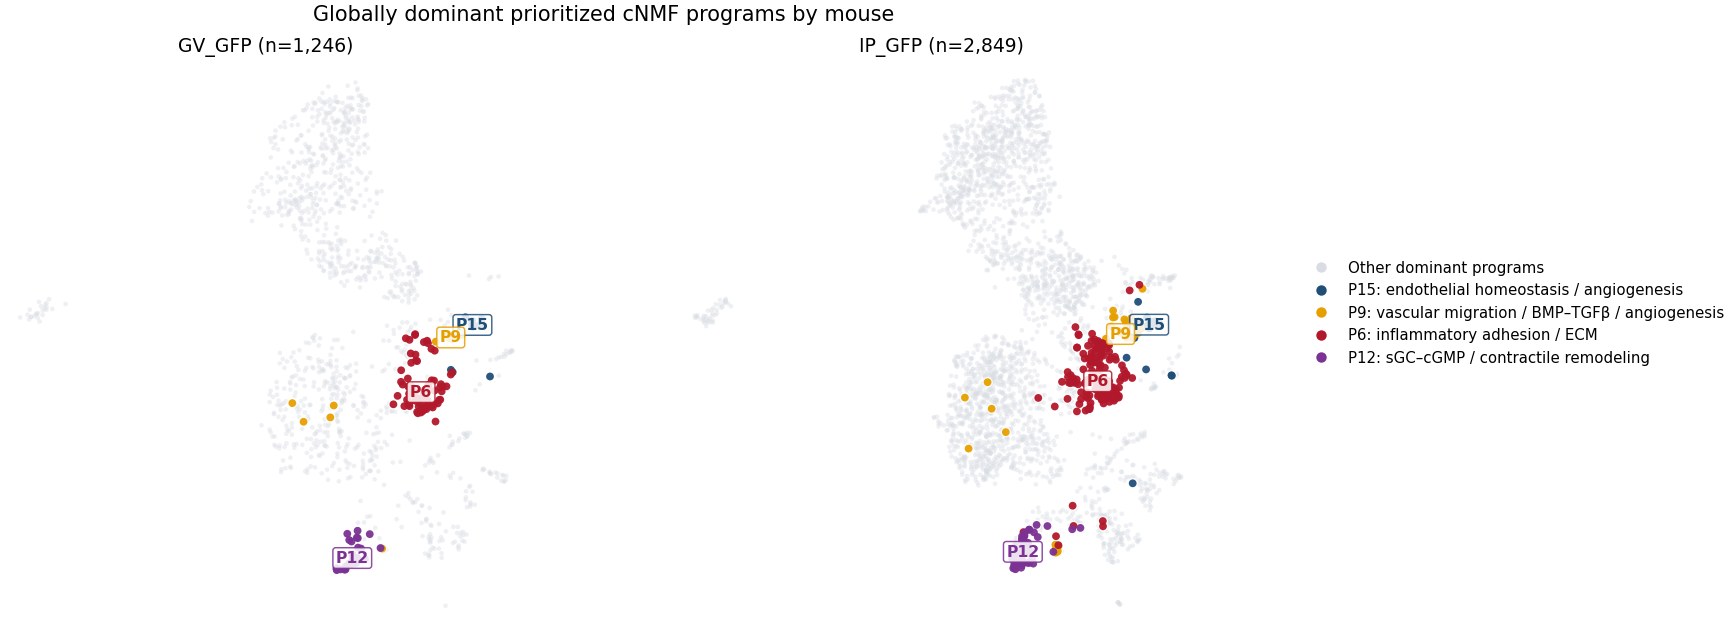

Saved:
/oak/stanford/groups/engreitz/Users/tri/10xPerturbSeq/analysis/250507_ePAH1_NovaSeq/CRISPR_count/IP_GV_unified_sceptre_cnmf_no_celltype/PerturbNMF/results/IP_GV_skcnmf_K30_dt2_0_n100/Evaluation/30_2_0/selected_program_umap/IP_GV_global_dominant_P15_P9_P6_P12_by_mouse.pdf
/oak/stanford/groups/engreitz/Users/tri/10xPerturbSeq/analysis/250507_ePAH1_NovaSeq/CRISPR_count/IP_GV_unified_sceptre_cnmf_no_celltype/PerturbNMF/results/IP_GV_skcnmf_K30_dt2_0_n100/Evaluation/30_2_0/selected_program_umap/IP_GV_global_dominant_P15_P9_P6_P12_by_mouse.svg
/oak/stanford/groups/engreitz/Users/tri/10xPerturbSeq/analysis/250507_ePAH1_NovaSeq/CRISPR_count/IP_GV_unified_sceptre_cnmf_no_celltype/PerturbNMF/results/IP_GV_skcnmf_K30_dt2_0_n100/Evaluation/30_2_0/selected_program_umap/IP_GV_global_dominant_P15_P9_P6_P12_by_mouse.png


In [8]:
samples = sorted(cell_table["sample"].unique().tolist())

if len(samples) == 0:
    raise ValueError("No sample labels were found.")

x_padding = 0.03 * (
    cell_table["UMAP1"].max() - cell_table["UMAP1"].min()
)
y_padding = 0.03 * (
    cell_table["UMAP2"].max() - cell_table["UMAP2"].min()
)
fixed_limits = (
    (
        float(cell_table["UMAP1"].min() - x_padding),
        float(cell_table["UMAP1"].max() + x_padding),
    ),
    (
        float(cell_table["UMAP2"].min() - y_padding),
        float(cell_table["UMAP2"].max() + y_padding),
    ),
)

fig, axes = plt.subplots(
    1,
    len(samples),
    figsize=PER_MOUSE_FIGSIZE,
    constrained_layout=True,
    squeeze=False,
)
axes = axes.ravel()

for axis_index, sample_name in enumerate(samples):
    current = cell_table.loc[
        cell_table["sample"] == sample_name
    ].copy()

    draw_selected_program_umap(
        axes[axis_index],
        current,
        title=f"{sample_name} (n={len(current):,})",
        show_legend=False,
        fixed_limits=fixed_limits,
    )

# One shared legend.
legend_elements = [
    Line2D(
        [0],
        [0],
        marker="o",
        linestyle="",
        markersize=5,
        markerfacecolor=BACKGROUND_COLOR,
        markeredgewidth=0,
        label="Other dominant programs",
    )
]
for program in SELECTED_PROGRAMS:
    legend_elements.append(
        Line2D(
            [0],
            [0],
            marker="o",
            linestyle="",
            markersize=5,
            markerfacecolor=PROGRAM_COLORS[program],
            markeredgewidth=0,
            label=f"P{program}: {PROGRAM_LABELS[program]}",
        )
    )

fig.legend(
    handles=legend_elements,
    loc="center left",
    bbox_to_anchor=(1.01, 0.5),
    frameon=False,
    fontsize=7.2,
)

fig.suptitle(
    "Globally dominant prioritized cNMF programs by mouse",
    fontsize=10,
)

mouse_pdf = OUTPUT_DIR / f"{OUTPUT_STEM}_by_mouse.pdf"
mouse_svg = OUTPUT_DIR / f"{OUTPUT_STEM}_by_mouse.svg"
mouse_png = OUTPUT_DIR / f"{OUTPUT_STEM}_by_mouse.png"

fig.savefig(mouse_pdf)
fig.savefig(mouse_svg)
fig.savefig(mouse_png, dpi=300)
plt.show()
plt.close(fig)

print("Saved:")
print(mouse_pdf)
print(mouse_svg)
print(mouse_png)


## Interpretation

A colored cell is not merely high for one of the four selected programs relative to those four programs. It is colored only when that program is the cell's **maximum-usage program across the complete K = 30 factorization**.

The light-gray background therefore includes:

- cells dominated by any of the other 26 programs;
- cells failing `MIN_DOMINANT_USAGE`, if a cutoff is enabled.

The plot shows where the four prioritized molecular states occur in the transcriptomic embedding. It does not by itself show that a perturbation caused those cells to occupy the state. Target-to-program effects should be evaluated with the CRT results.